<a href="https://colab.research.google.com/github/Shreyashgol/phonetic-guided-speech-generation/blob/main/notebooks/01_dataset_overview.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ---- Cell 0: Re-extract the dataset (run first in every NEW Colab session)
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_ROOT = '/content/drive/MyDrive/phonetic-tts'
archive_path = os.path.join(PROJECT_ROOT, 'data/raw/LJSpeech-1.1.tar.bz2')
print('Archive in Drive:', os.path.exists(archive_path))

if not os.path.isdir('/content/LJSpeech-1.1'):
    !tar -xjf "{archive_path}" -C /content
print('Number of wavs:', len(os.listdir('/content/LJSpeech-1.1/wavs')))  # expect 13100

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archive in Drive: True
Number of wavs: 13100


In [ ]:
# ---- Cell 1: Standard start-of-notebook setup
from google.colab import drive
drive.mount('/content/drive')

import os, sys
PROJECT_ROOT = '/content/drive/MyDrive/phonetic-tts'
sys.path.insert(0, PROJECT_ROOT)

from src.utils.config import load_config
cfg = load_config(PROJECT_ROOT)
RAW = cfg['abs_paths']['raw']
RESULTS = cfg['abs_paths']['results']
os.makedirs(RESULTS, exist_ok=True)
print('Raw data:', RAW, '| exists:', os.path.isdir(RAW))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Raw data: /content/LJSpeech-1.1 | exists: True


In [ ]:
# ---- Cell 2: Load metadata (pipe-separated, no header, quotes must NOT be interpreted)
import pandas as pd, csv

meta = pd.read_csv(
    os.path.join(RAW, 'metadata.csv'),
    sep='|', header=None, names=['id', 'raw_text', 'norm_text'],
    quoting=csv.QUOTE_NONE, encoding='utf-8'
)
print('Rows:', len(meta))
print('Missing norm_text:', meta['norm_text'].isna().sum())
print('Duplicate IDs:', meta['id'].duplicated().sum())
meta.head(10)

Rows: 13100
Missing norm_text: 0
Duplicate IDs: 0


,id,raw_text,norm_text
0,LJ001-0001,"Printing, in the only sense with which we are ...","Printing, in the only sense with which we are ..."
1,LJ001-0002,in being comparatively modern.,in being comparatively modern.
2,LJ001-0003,For although the Chinese took impressions from...,For although the Chinese took impressions from...
3,LJ001-0004,"produced the block books, which were the immed...","produced the block books, which were the immed..."
4,LJ001-0005,the invention of movable metal letters in the ...,the invention of movable metal letters in the ...
5,LJ001-0006,"And it is worth mention in passing that, as an...","And it is worth mention in passing that, as an..."
6,LJ001-0007,"the earliest book printed with movable types, ...","the earliest book printed with movable types, ..."
7,LJ001-0008,has never been surpassed.,has never been surpassed.
8,LJ001-0009,"Printing, then, for our purpose, may be consid...","Printing, then, for our purpose, may be consid..."
9,LJ001-0010,"Now, as all books not primarily intended as pi...","Now, as all books not primarily intended as pi..."


In [ ]:
# ---- Cell 3: Raw vs normalized text: where do they differ?
diff = meta[meta['raw_text'] != meta['norm_text']].dropna()
print('Rows where raw != normalized:', len(diff), f'({len(diff)/len(meta):.1%})')
pd.set_option('display.max_colwidth', 120)
diff.sample(8, random_state=0)[['id', 'raw_text', 'norm_text']]

Rows where raw != normalized: 1505 (11.5%)


,id,raw_text,norm_text
9768,LJ037-0156,also examined the four cartridge cases found near the site of the homicide and compared them with the test cartridge...,also examined the four cartridge cases found near the site of the homicide and compared them with the test cartridge...
91,LJ001-0092,"The Chiswick press in 1844 revived Caslon's founts, printing for Messrs. Longman the Diary of Lady Willoughby.","The Chiswick press in eighteen forty-four revived Caslon's founts, printing for Messrs. Longman the Diary of Lady Wi..."
12690,LJ049-0098,In 1902 bills passed both Houses of Congress but failed of enactment when the Senate refused to accept the conferenc...,In nineteen oh two bills passed both Houses of Congress but failed of enactment when the Senate refused to accept th...
10477,LJ040-0044,Oswald apparently started reading about communism when he was about 15.,Oswald apparently started reading about communism when he was about fifteen.
9510,LJ036-0116,Lee Oswald was No. 3;,Lee Oswald was Number three;
2465,LJ009-0179,"the most recent enactment in force was the 9th George IV. cap. 31, which directed the dissection of all bodies of ex...","the most recent enactment in force was the ninth George the fourth cap. thirty-one, which directed the dissection of..."
1056,LJ004-0187,"Already, as early as 1818, a prison existed at Bury St. Edmunds which was a model for imitation to others at that time,","Already, as early as eighteen eighteen, a prison existed at Bury St. Edmunds which was a model for imitation to othe..."
9817,LJ037-0205,"The invoice was prepared on March 13, 1963; the revolver was actually shipped on March 20 by Railway Express.","The invoice was prepared on March thirteen, nineteen sixty-three; the revolver was actually shipped on March twenty ..."


In [ ]:
# ---- Cell 4: Audio properties for ALL files (header read only, fast)
import soundfile as sf
from tqdm import tqdm

rows = []
for cid in tqdm(meta['id']):
    info = sf.info(os.path.join(RAW, 'wavs', f'{cid}.wav'))
    rows.append((cid, info.samplerate, info.channels, info.subtype, info.duration))

audio = pd.DataFrame(rows, columns=['id', 'sr', 'channels', 'subtype', 'duration'])
print(audio['sr'].value_counts())
print(audio['channels'].value_counts())
print(audio['subtype'].value_counts())

100%|██████████| 13100/13100 [00:06<00:00, 2062.65it/s]

sr
22050    13100
Name: count, dtype: int64
channels
1    13100
Name: count, dtype: int64
subtype
PCM_16    13100
Name: count, dtype: int64


Total hours : 23.92
Min / Max   : 1.11 s / 10.10 s
Mean / Median: 6.57 s / 6.76 s
count    13100.000000
mean         6.573823
std          2.185431
min          1.110068
25%          4.987800
50%          6.764127
75%          8.389524
max         10.096190
Name: duration, dtype: float64


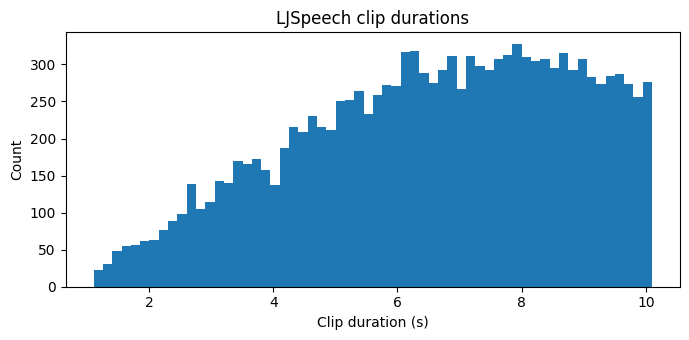

In [ ]:
# ---- Cell 5: Duration statistics and histogram
import matplotlib.pyplot as plt

d = audio['duration']
print(f'Total hours : {d.sum()/3600:.2f}')
print(f'Min / Max   : {d.min():.2f} s / {d.max():.2f} s')
print(f'Mean / Median: {d.mean():.2f} s / {d.median():.2f} s')
print(d.describe())

plt.figure(figsize=(7,3.5))
plt.hist(d, bins=60)
plt.xlabel('Clip duration (s)'); plt.ylabel('Count'); plt.title('LJSpeech clip durations')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS, '01_clip_duration_hist.png'), dpi=150)
plt.show()

            n_chars       n_words  words_per_sec
count  13100.000000  13100.000000   13100.000000
mean      99.898779     16.986565       2.593684
std       33.952214      6.063484       0.416202
min       12.000000      1.000000       0.864672
25%       76.000000     13.000000       2.316454
50%      102.000000     17.000000       2.580559
75%      126.000000     21.000000       2.856457
max      187.000000     39.000000       4.662212


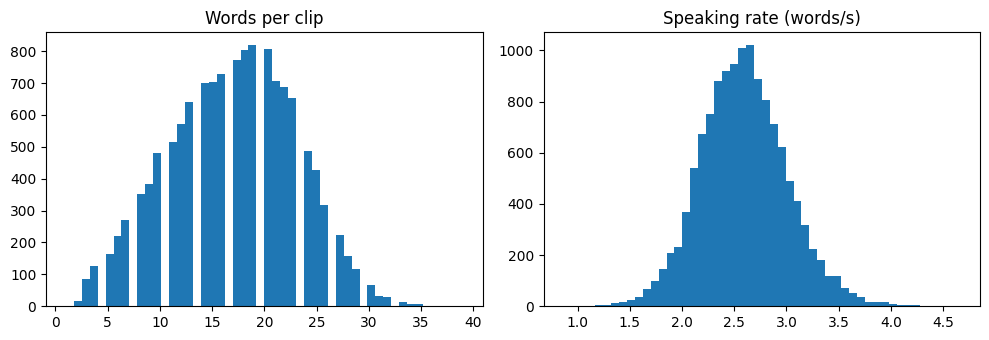

In [ ]:
# ---- Cell 6: Transcript length and speaking rate
df = meta.merge(audio, on='id')
df['norm_text'] = df['norm_text'].fillna(df['raw_text'])   # fall back if norm is missing
df['n_chars'] = df['norm_text'].str.len()
df['n_words'] = df['norm_text'].str.split().str.len()
df['words_per_sec'] = df['n_words'] / df['duration']

print(df[['n_chars', 'n_words', 'words_per_sec']].describe())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(df['n_words'], bins=50);       ax[0].set_title('Words per clip')
ax[1].hist(df['words_per_sec'], bins=50); ax[1].set_title('Speaking rate (words/s)')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS, '01_text_and_rate_hist.png'), dpi=150)
plt.show()

In [ ]:
# ---- Cell 7: Pick 5 clips to listen to (2 short, 2 long, 1 with digits/quotes in the raw text)
short = df.nsmallest(2, 'duration')['id'].tolist()
long_ = df.nlargest(2, 'duration')['id'].tolist()
odd = df[df['raw_text'].str.contains(r'\d', na=False)].sample(1, random_state=1)['id'].tolist()
picks = short + long_ + odd

import IPython.display as ipd
for cid in picks:
    r = df[df['id'] == cid].iloc[0]
    print(f"\n{cid} | {r['duration']:.2f}s")
    print('RAW :', r['raw_text'])
    print('NORM:', r['norm_text'])
    ipd.display(ipd.Audio(os.path.join(RAW, 'wavs', f'{cid}.wav')))


LJ021-0165 | 1.11s
RAW : On the contrary,
NORM: On the contrary,



LJ037-0076 | 1.11s
RAW : Two young women,
NORM: Two young women,



LJ002-0321 | 10.10s
RAW : others who arrived just after the time of distribution were often forty-eight hours without food. The latter might also be six days without meat.
NORM: others who arrived just after the time of distribution were often forty-eight hours without food. The latter might also be six days without meat.



LJ003-0007 | 10.10s
RAW : hundreds of women and children came in every morning to spend the day there, and there was no limitation whatever to the numbers of visitors admitted to the debtors' side.
NORM: hundreds of women and children came in every morning to spend the day there, and there was no limitation whatever to the numbers of visitors admitted to the debtors' side.



LJ003-0054 | 8.94s
RAW : An imperfect attempt at classification was, however, made in 1812, and a yard was as far as possible set apart for the untried,
NORM: An imperfect attempt at classification was, however, made in eighteen twelve, and a yard was as far as possible set apart for the untried,


Clip LJ002-0321: lead silence 0.000s | trail silence 0.088s


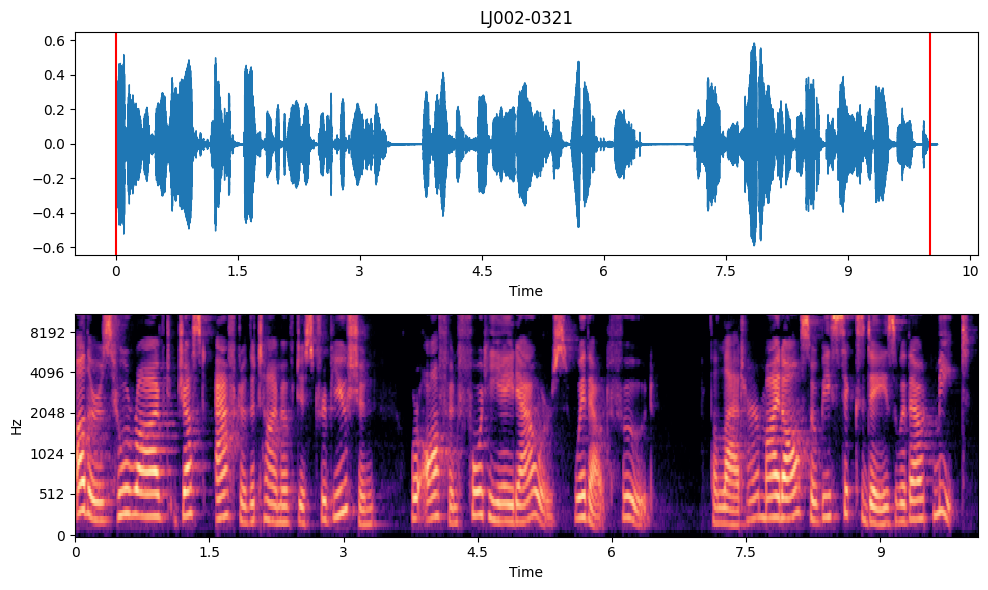

Frames in this clip: 870 | expected ~ 870


In [ ]:
# ---- Cell 8: Waveform + mel spectrogram for one clip, with leading/trailing silence marked
import librosa, librosa.display, numpy as np

a = cfg['audio']
cid = picks[2]
y, sr = librosa.load(os.path.join(RAW, 'wavs', f'{cid}.wav'), sr=a['sample_rate'])

_, (start, end) = librosa.effects.trim(y, top_db=30)
print(f'Clip {cid}: lead silence {start/sr:.3f}s | trail silence {(len(y)-end)/sr:.3f}s')

mel = librosa.feature.melspectrogram(
    y=y, sr=sr, n_fft=a['n_fft'], hop_length=a['hop_length'],
    n_mels=a['n_mels'], fmin=a['f_min'], fmax=a['f_max'])
mel_db = librosa.power_to_db(mel, ref=np.max)

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
librosa.display.waveshow(y, sr=sr, ax=ax[0])
ax[0].axvline(start/sr, color='r'); ax[0].axvline(end/sr, color='r'); ax[0].set_title(cid)
librosa.display.specshow(mel_db, sr=sr, hop_length=a['hop_length'], x_axis='time', y_axis='mel', ax=ax[1])
plt.tight_layout()
plt.savefig(os.path.join(RESULTS, '01_wave_and_mel.png'), dpi=150)
plt.show()
print('Frames in this clip:', mel.shape[1], '| expected ~', int(len(y)/a['hop_length'])+1)

In [ ]:
# ---- Cell 9: Alignment risk scan
import re
from collections import Counter

# (a) Characters that are not letters, space or basic punctuation
char_counts = Counter(''.join(df['norm_text']))
odd_chars = {c: n for c, n in char_counts.items() if not re.match(r"[A-Za-z .,;:!?'\-\"()]", c)}
print('Unusual characters:', odd_chars)

# (b) Digits left in the normalized text (these will not be in the dictionary)
digits = df[df['norm_text'].str.contains(r'\d')]
print('Normalized rows still containing digits:', len(digits))

# (c) Vocabulary and rare words
words = Counter(w.lower().strip('.,;:!?"()') for t in df['norm_text'] for w in t.split())
print('Vocabulary size:', len(words))
print('Words seen only once:', sum(1 for w, n in words.items() if n == 1))

# (d) Very short clips and very fast/slow speech
print('Clips < 1.5 s:', (df['duration'] < 1.5).sum())
print('Fastest 5 clips (words/s):')
print(df.nlargest(5, 'words_per_sec')[['id', 'duration', 'words_per_sec']])

Unusual characters: {'â': 1, 'é': 2, 'à': 1, 'ê': 1, 'ü': 15, 'è': 1, '“': 3, '”': 3, '’': 1, '[': 7, ']': 7}
Normalized rows still containing digits: 0
Vocabulary size: 14775
Words seen only once: 6089
Clips < 1.5 s: 82
Fastest 5 clips (words/s):
               id  duration  words_per_sec
9527   LJ036-0133  7.507166       4.662212
9534   LJ036-0140  7.274966       4.536104
7660   LJ028-0403  2.015646       4.465069
11711  LJ045-0161  2.689025       4.462584
1942   LJ007-0217  1.121678       4.457607


In [ ]:
# ---- Cell 10: Save the summary for the report (this is what Notebook 09 will read)
summary = {
    'n_clips': int(len(df)),
    'total_hours': round(float(df['duration'].sum()/3600), 2),
    'mean_duration_s': round(float(df['duration'].mean()), 2),
    'max_duration_s': round(float(df['duration'].max()), 2),
    'sample_rates': {int(k): int(v) for k, v in audio['sr'].value_counts().items()},
    'mean_words_per_sec': round(float(df['words_per_sec'].mean()), 2),
    'vocab_size': len(words),
    'rows_raw_neq_norm': int(len(diff)),
}
import json
with open(os.path.join(RESULTS, '01_dataset_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
df.to_csv(os.path.join(cfg['abs_paths']['processed'], 'metadata_with_stats.csv'), index=False)

{
  "n_clips": 13100,
  "total_hours": 23.92,
  "mean_duration_s": 6.57,
  "max_duration_s": 10.1,
  "sample_rates": {
    "22050": 13100
  },
  "mean_words_per_sec": 2.59,
  "vocab_size": 14775,
  "rows_raw_neq_norm": 1505
}
